In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib

from scipy.sparse import load_npz

from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

In [2]:
# Original training data
X_train = load_npz("processed_data/X_train_processed.npz")
y_train = pd.read_csv("processed_data/y_train.csv").squeeze()

# Validation data
X_val = load_npz("processed_data/X_val_processed.npz")
y_val = pd.read_csv("processed_data/y_val.csv").squeeze()

# Testing data
X_test = load_npz("processed_data/X_test_processed.npz")
y_test = pd.read_csv("processed_data/y_test.csv").squeeze()

print("Training Shape:", X_train.shape)
print("Validation Shape:", X_val.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (1037340, 1258)
Validation Shape: (259335, 1258)
Testing Shape: (555719, 1258)


In [3]:
# SMOTE
X_train_smote = load_npz(
    "processed_data/imbalance/X_train_smote.npz"
)
y_train_smote = pd.read_csv(
    "processed_data/imbalance/y_train_smote.csv"
).squeeze()

# Random Undersampling
X_train_under = load_npz(
    "processed_data/imbalance/X_train_under.npz"
)
y_train_under = pd.read_csv(
    "processed_data/imbalance/y_train_under.csv"
).squeeze()

# Random Oversampling
X_train_over = load_npz(
    "processed_data/imbalance/X_train_over.npz"
)
y_train_over = pd.read_csv(
    "processed_data/imbalance/y_train_over.csv"
).squeeze()

print("SMOTE Shape:", X_train_smote.shape)
print("Undersampling Shape:", X_train_under.shape)
print("Oversampling Shape:", X_train_over.shape)

SMOTE Shape: (1134468, 1258)
Undersampling Shape: (66055, 1258)
Oversampling Shape: (1134468, 1258)


In [17]:
from sklearn.base import clone

models = {
    "Logistic Regression": LogisticRegression(
        solver="saga",
        max_iter=1000,
        random_state=42
    ),

    "SGD Classifier": SGDClassifier(
        loss="log_loss",
        max_iter=1000,
        random_state=42,
        tol=0.001
    )
}

In [18]:
results = []
trained_models = {}

for dataset_name, (X_resampled, y_resampled) in training_datasets.items():

    print("\n" + "=" * 50)
    print("Training Dataset:", dataset_name)
    print("=" * 50)

    for model_name, base_model in models.items():

        print("\nTraining:", model_name)

        # Create a separate model for every experiment
        model = clone(base_model)

        model.fit(X_resampled, y_resampled)

        y_pred = model.predict(X_val)
        y_prob = model.predict_proba(X_val)[:, 1]

        accuracy = accuracy_score(y_val, y_pred)
        precision = precision_score(y_val, y_pred, zero_division=0)
        recall = recall_score(y_val, y_pred, zero_division=0)
        f1 = f1_score(y_val, y_pred, zero_division=0)
        roc_auc = roc_auc_score(y_val, y_prob)
        pr_auc = average_precision_score(y_val, y_prob)

        results.append({
            "Dataset": dataset_name,
            "Model": model_name,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1 Score": f1,
            "ROC-AUC": roc_auc,
            "PR-AUC": pr_auc
        })

        # Store the independent trained model
        trained_models[(dataset_name, model_name)] = model

        print("Precision:", round(precision, 4))
        print("Recall:", round(recall, 4))
        print("F1 Score:", round(f1, 4))
        print("PR-AUC:", round(pr_auc, 4))


Training Dataset: Original

Training: Logistic Regression


/Users/rahulmanchanda/Desktop/Machine Learning -Credit Card Fraud Detection /venv/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Precision: 0.0
Recall: 0.0
F1 Score: 0.0
PR-AUC: 0.2287

Training: SGD Classifier
Precision: 0.0
Recall: 0.0
F1 Score: 0.0
PR-AUC: 0.2339

Training Dataset: SMOTE

Training: Logistic Regression


/Users/rahulmanchanda/Desktop/Machine Learning -Credit Card Fraud Detection /venv/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Precision: 0.3622
Recall: 0.5436
F1 Score: 0.4347
PR-AUC: 0.2388

Training: SGD Classifier
Precision: 0.3753
Recall: 0.5416
F1 Score: 0.4434
PR-AUC: 0.2472

Training Dataset: Undersampling

Training: Logistic Regression


/Users/rahulmanchanda/Desktop/Machine Learning -Credit Card Fraud Detection /venv/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Precision: 0.3772
Recall: 0.5423
F1 Score: 0.4449
PR-AUC: 0.2464

Training: SGD Classifier
Precision: 0.3216
Recall: 0.5849
F1 Score: 0.415
PR-AUC: 0.2358

Training Dataset: Oversampling

Training: Logistic Regression


/Users/rahulmanchanda/Desktop/Machine Learning -Credit Card Fraud Detection /venv/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Precision: 0.3644
Recall: 0.5416
F1 Score: 0.4357
PR-AUC: 0.2426

Training: SGD Classifier
Precision: 0.3619
Recall: 0.5343
F1 Score: 0.4315
PR-AUC: 0.2445


In [28]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="PR-AUC",
    ascending=False
)

display(results_df.round(4))

,Dataset,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
3,SMOTE,SGD Classifier,0.9921,0.3753,0.5416,0.4434,0.8972,0.2472
4,Undersampling,Logistic Regression,0.9922,0.3772,0.5423,0.4449,0.9002,0.2464
7,Oversampling,SGD Classifier,0.9919,0.3619,0.5343,0.4315,0.8975,0.2445
6,Oversampling,Logistic Regression,0.9919,0.3644,0.5416,0.4357,0.9054,0.2426
2,SMOTE,Logistic Regression,0.9918,0.3622,0.5436,0.4347,0.9040,0.2388
5,Undersampling,SGD Classifier,0.9905,0.3216,0.5849,0.4150,0.8939,0.2358
1,Original,SGD Classifier,0.9937,0.0000,0.0000,0.0000,0.8425,0.2339
0,Original,Logistic Regression,0.9937,0.0000,0.0000,0.0000,0.8495,0.2287


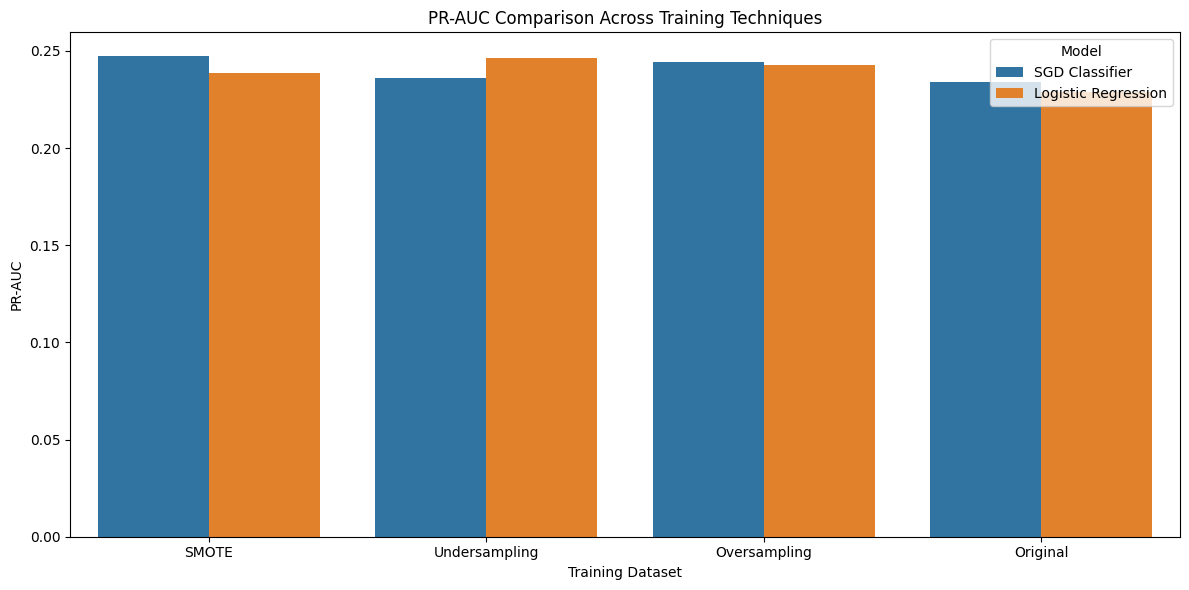

In [29]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Dataset",
    y="PR-AUC",
    hue="Model"
)

plt.title("PR-AUC Comparison Across Training Techniques")
plt.xlabel("Training Dataset")
plt.ylabel("PR-AUC")
plt.legend(title="Model")
plt.tight_layout()
plt.show()

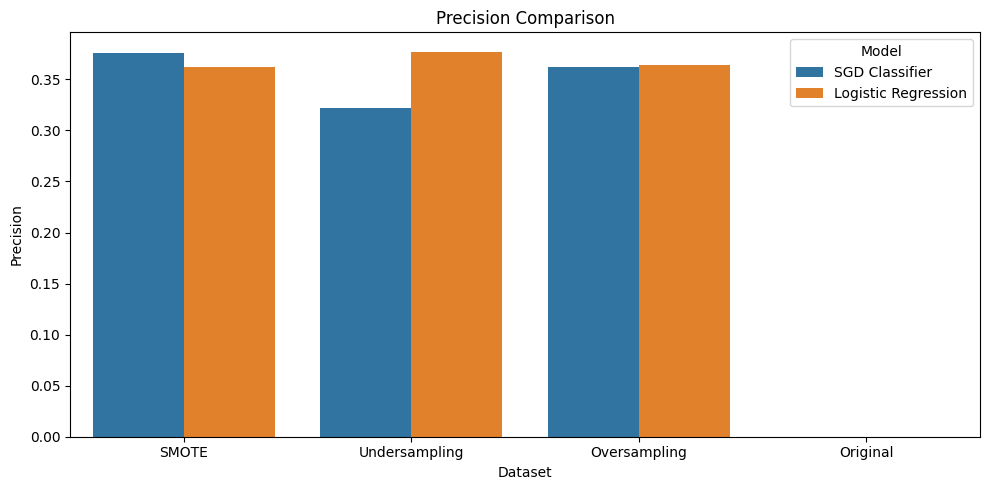

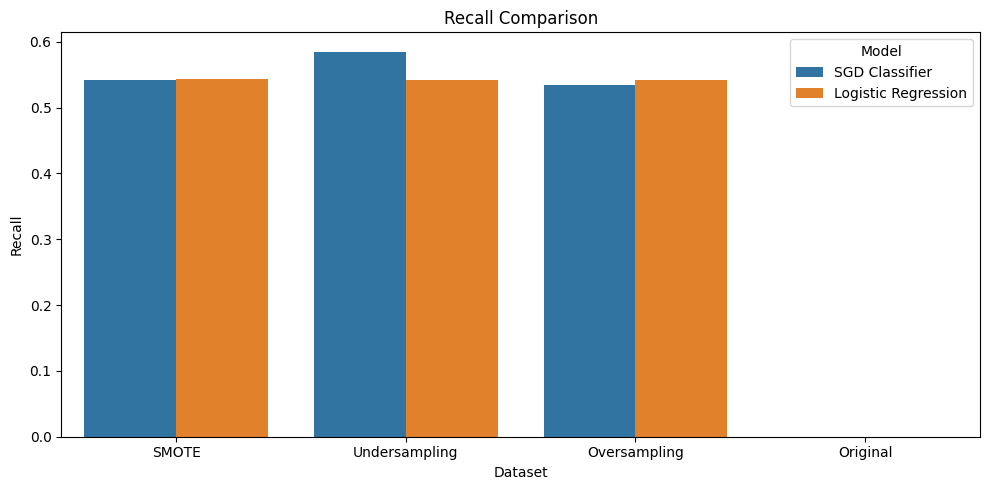

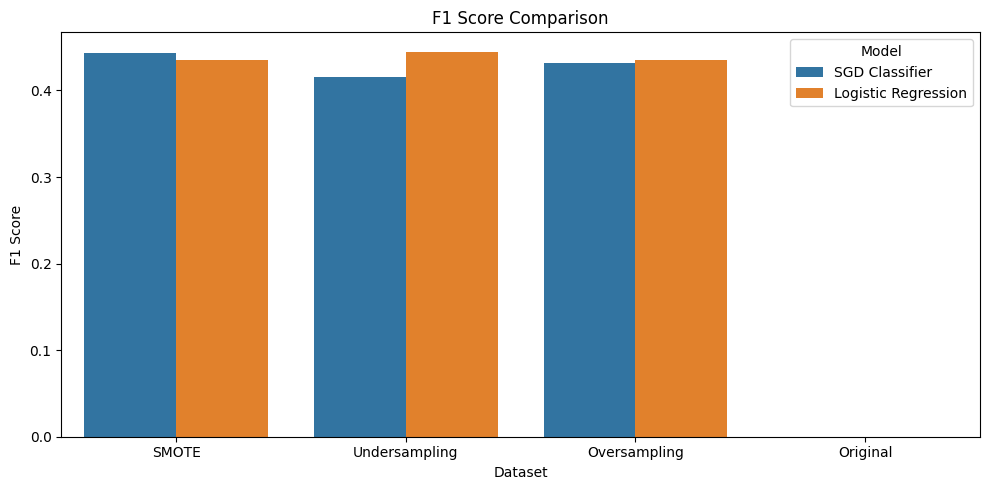

In [30]:
metrics = ["Precision", "Recall", "F1 Score"]

for metric in metrics:

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=results_df,
        x="Dataset",
        y=metric,
        hue="Model"
    )

    plt.title(f"{metric} Comparison")
    plt.tight_layout()
    plt.show()

In [31]:
best_result = results_df.iloc[0]

best_dataset = best_result["Dataset"]
best_model_name = best_result["Model"]

best_model = trained_models[
    (best_dataset, best_model_name)
]

print("Best Training Technique:", best_dataset)
print("Best Model:", best_model_name)
print("Validation PR-AUC:", round(best_result["PR-AUC"], 4))

Best Training Technique: SMOTE
Best Model: SGD Classifier
Validation PR-AUC: 0.2472


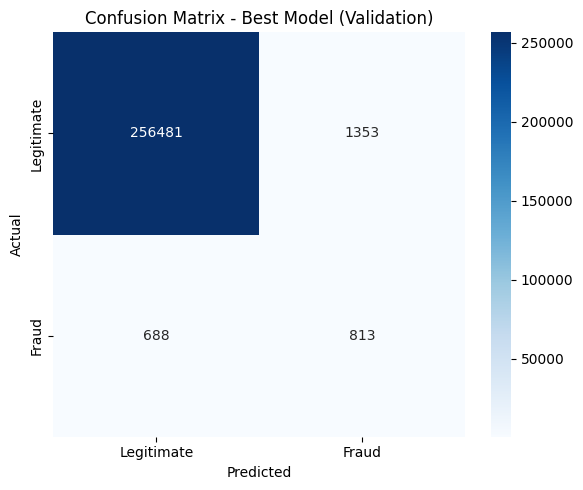

In [32]:
y_val_pred = best_model.predict(X_val)

cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.title("Confusion Matrix - Best Model (Validation)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [33]:
print("Classification Report - Validation")

print(
    classification_report(
        y_val,
        y_val_pred,
        target_names=["Legitimate", "Fraud"],
        zero_division=0
    )
)

Classification Report - Validation
              precision    recall  f1-score   support

  Legitimate       1.00      0.99      1.00    257834
       Fraud       0.38      0.54      0.44      1501

    accuracy                           0.99    259335
   macro avg       0.69      0.77      0.72    259335
weighted avg       0.99      0.99      0.99    259335



In [34]:
os.makedirs("../reports", exist_ok=True)

results_df.to_csv(
    "../reports/model_comparison.csv",
    index=False
)

print("Model comparison results saved successfully!")

Model comparison results saved successfully!


In [35]:
# Final predictions
y_test_pred = best_model.predict(X_test)
y_test_prob = best_model.predict_proba(X_test)[:, 1]

# Final evaluation
print("FINAL TEST RESULTS")

print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_test_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_test_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_test_prob))
print("PR-AUC:", average_precision_score(y_test, y_test_prob))

FINAL TEST RESULTS
Accuracy: 0.9926347668515922
Precision: 0.25903018307768433
Recall: 0.4881118881118881
F1 Score: 0.33845159204784225
ROC-AUC: 0.8581553563572226
PR-AUC: 0.15485146124787028


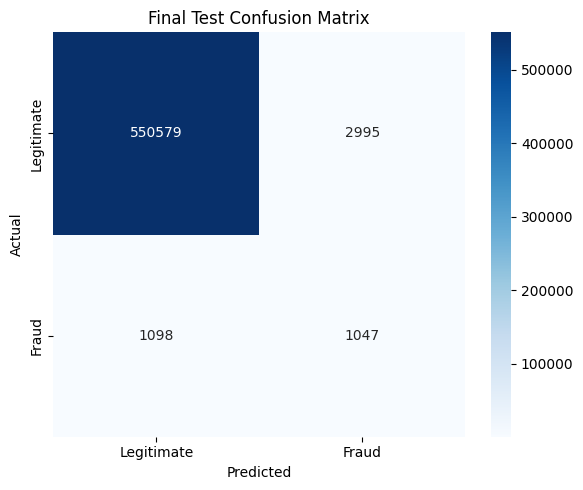

In [36]:
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.title("Final Test Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [37]:
os.makedirs("../models", exist_ok=True)

joblib.dump(
    best_model,
    "../models/best_model.pkl"
)

print("Best model saved successfully!")

Best model saved successfully!
